# 10 - scikit-learn

**Sources:** Summer School *CursP_sklearn* ("Part IV: Scikits": datasets, clustering with k-means, distances &
kernels, curse of dimensionality, PCA / LDA, kNN and SVC, metrics, cross-validation, and the "Eigenfaces"
practical session).

**Modern notes:** `load_boston` was removed (ethical issues) -> use `fetch_california_housing` or
`load_diabetes`; `sklearn.cross_validation` -> `sklearn.model_selection`; the slides call
`metrics.recall_score(yPred, y)` with the arguments **swapped** - the signature is `(y_true, y_pred)`.
The Eigenfaces session needs a private image database, so we use the built-in **digits** images instead
(same pipeline: images -> vectors -> scale -> PCA -> "eigen-images" -> clustering -> classification).

**The scikit-learn API in one sentence:** every model is an *estimator* with `fit(X, y)`; predictors add
`predict(X)` / `score(X, y)`; transformers add `transform(X)` / `fit_transform(X)`. `X` has shape
`(n_samples, n_features)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
print(sklearn.__version__)
rng = np.random.default_rng(0)

1.9.1


## 1. Datasets
Three kinds: **toy datasets** (`load_*`), **real-world fetchers** (`fetch_*`, downloaded), **generators**
(`make_*`). All `load_*` return a `Bunch` (dict with attribute access) with `data`, `target`, `feature_names`,
`DESCR`.

(150, 4) (150,) [0 1 2] ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] ['setosa' 'versicolor' 'virginica']
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]
['load_breast_cancer', 'load_diabetes', 'load_digits', 'load_files', 'load_iris', 'load_linnerud', 'load_sample_image', 'load_sample_images', 'load_svmlight_file', 'load_svmlight_files', 'load_wine']


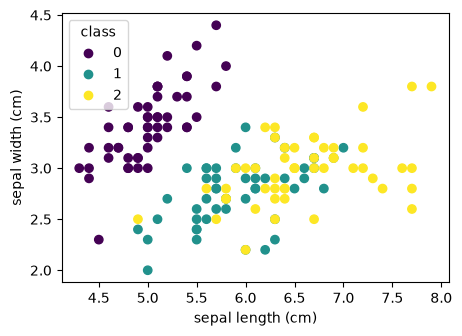

In [2]:
from sklearn import datasets

iris = datasets.load_iris()
X, y = iris.data, iris.target
print(X.shape, y.shape, np.unique(y), iris.feature_names, iris.target_names)
print(X[:2])
print(sorted(k for k in dir(datasets) if k.startswith("load_")))

fig, ax = plt.subplots(figsize=(5, 3.5))
sc = ax.scatter(X[:, 0], X[:, 1], c=y)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
ax.legend(*sc.legend_elements(), title="class")
plt.show()

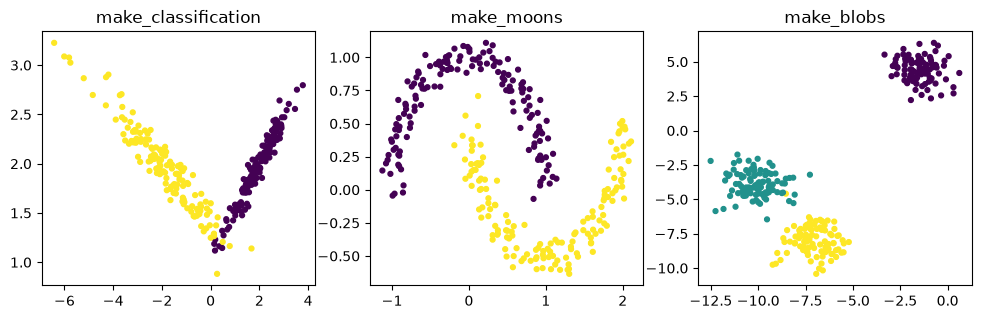

In [3]:
# Generators: classification, regression, blobs, moons, swiss roll
Xc, yc = datasets.make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                                      n_clusters_per_class=1, class_sep=2.0, random_state=1)
Xm, ym = datasets.make_moons(300, noise=0.08, random_state=1)
Xb, yb = datasets.make_blobs(300, centers=3, cluster_std=0.9, random_state=1)
Xs, ts = datasets.make_swiss_roll(1000, noise=0.05, random_state=1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, (A, lab, t) in zip(axes, [(Xc, yc, "make_classification"), (Xm, ym, "make_moons"), (Xb, yb, "make_blobs")]):
    ax.scatter(A[:, 0], A[:, 1], c=lab, s=12); ax.set_title(t)
plt.show()

**Challenge (slides, 5 min):** generate and plot a dataset with **two non-overlapping swiss rolls** in 3-D,
1 000 samples each. Tip: rotate and shift the second one (`scipy.spatial.transform.Rotation`).

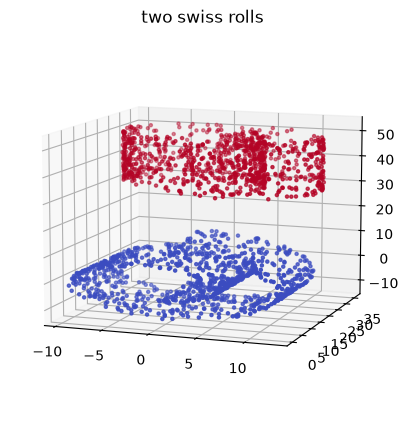

In [4]:
from scipy.spatial.transform import Rotation

roll1, t1 = datasets.make_swiss_roll(1000, noise=0.05, random_state=1)
roll2, t2 = datasets.make_swiss_roll(1000, noise=0.05, random_state=2)
roll2 = Rotation.from_euler("xyz", [90, 0, 0], degrees=True).apply(roll2) + [0, 25, 30]    # one possible solution
two_rolls = np.vstack([roll1, roll2])
roll_labels = np.r_[np.zeros(1000, int), np.ones(1000, int)]

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*two_rolls.T, c=roll_labels, s=5, cmap="coolwarm")
ax.set_title("two swiss rolls"); ax.view_init(10, -70)
plt.show()

## 2. Distances, similarities and kernels
A **metric** satisfies: $d(x,y)\ge0$, $d(x,y)=0 \iff x=y$, symmetry, and the triangle inequality. The Minkowski family
$\|x-y\|_p=(\sum_i |x_i-y_i|^p)^{1/p}$ gives Manhattan ($p=1$), Euclidean ($p=2$), Chebyshev ($p=\infty$).
Distance -> similarity (kernel): $s=e^{-d/\gamma}$ or the **RBF kernel** $K(x,y)=e^{-\gamma\|x-y\|^2}$.

In [5]:
from sklearn.metrics import pairwise
from scipy.spatial.distance import cdist

A = rng.normal(size=(4, 3))
D = pairwise.euclidean_distances(A)
print(D.round(2))
print(np.allclose(D, cdist(A, A)), np.allclose(D, np.linalg.norm(A[:, None] - A[None], axis=-1)))   # broadcasting version
print(pairwise.manhattan_distances(A).round(2)[0], pairwise.cosine_similarity(A).round(2)[0])
print(pairwise.rbf_kernel(A, gamma=0.5).round(2)[0])

[[0.   0.49 2.09 1.59]
 [0.49 0.   2.18 1.41]
 [2.09 2.18 0.   3.1 ]
 [1.59 1.41 3.1  0.  ]]
True True
[0.   0.7  3.6  2.48] [ 1.    0.72 -0.35 -0.05]
[1.   0.89 0.11 0.28]


## 3. Unsupervised learning: clustering
Group objects so that those in a cluster are more similar to each other than to other clusters. Families:
**partitional** (k-means), **hierarchical** (agglomerative), **density-based** (DBSCAN), **graph/spectral**.

### k-means (MacQueen, 1967)
1. choose `k`; 2. guess `k` centres; 3. assign each point to the nearest centre; 4. move centres to the centroid of
their points; 5. repeat 3-4 until nothing changes (converges, but maybe to a **local optimum** -> use several `n_init`).

Let's write it from scratch first - 12 lines of NumPy.

inertia (sum of squared distances to centre): 466.8 | centres:
 [[ -1.47   4.41]
 [-10.06  -3.91]
 [ -7.03  -8.03]]


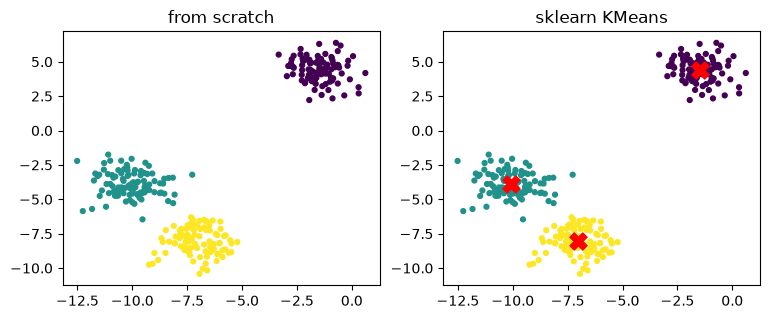

In [6]:
def kmeans(X, k, n_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    centres = X[rng.choice(len(X), k, replace=False)]
    for _ in range(n_iter):
        labels = np.argmin(((X[:, None, :] - centres[None]) ** 2).sum(-1), axis=1)       # assignment
        new = np.array([X[labels == j].mean(0) if np.any(labels == j) else centres[j] for j in range(k)])
        if np.allclose(new, centres):
            break
        centres = new
    return labels, centres

labels_mine, centres_mine = kmeans(Xb, 3)

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xb)
print("inertia (sum of squared distances to centre):", round(km.inertia_, 1), "| centres:\n", km.cluster_centers_.round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].scatter(*Xb.T, c=labels_mine, s=12); axes[0].set_title("from scratch")
axes[1].scatter(*Xb.T, c=km.labels_, s=12); axes[1].scatter(*km.cluster_centers_.T, c="red", marker="X", s=150); axes[1].set_title("sklearn KMeans")
plt.show()

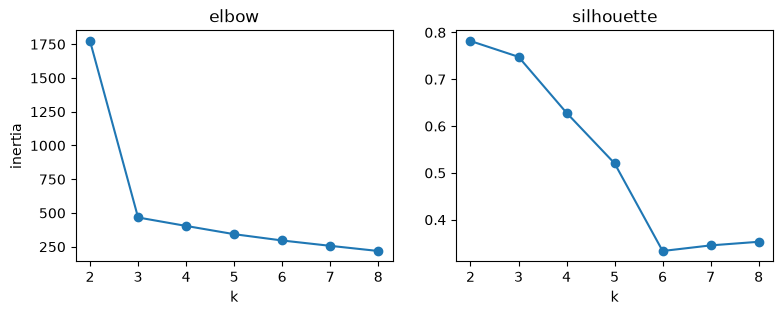

best k by silhouette: 2


In [7]:
# Choosing k: elbow (inertia) and silhouette score (-1..1, higher = better separated)
from sklearn.metrics import silhouette_score
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xb)
    inertias.append(m.inertia_); sils.append(silhouette_score(Xb, m.labels_))
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(ks, inertias, "o-"); axes[0].set(title="elbow", xlabel="k", ylabel="inertia")
axes[1].plot(ks, sils, "o-"); axes[1].set(title="silhouette", xlabel="k")
plt.show()
print("best k by silhouette:", list(ks)[int(np.argmax(sils))])

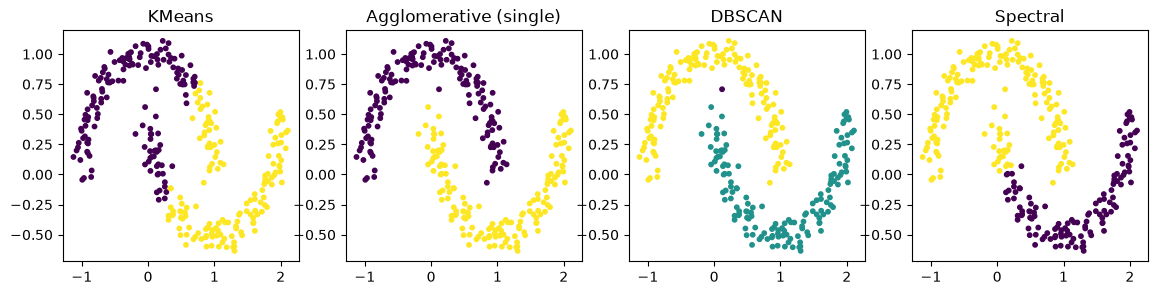

In [8]:
# k-means assumes round, similar-sized clusters. Compare algorithms on non-convex shapes (moons) and the 2 swiss rolls
algos = {
    "KMeans": KMeans(2, n_init=10, random_state=0),
    "Agglomerative (single)": AgglomerativeClustering(2, linkage="single"),
    "DBSCAN": DBSCAN(eps=0.2, min_samples=5),
    "Spectral": SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, algo) in zip(axes, algos.items()):
    lab = algo.fit_predict(Xm)
    ax.scatter(*Xm.T, c=lab, s=10); ax.set_title(name)
plt.show()

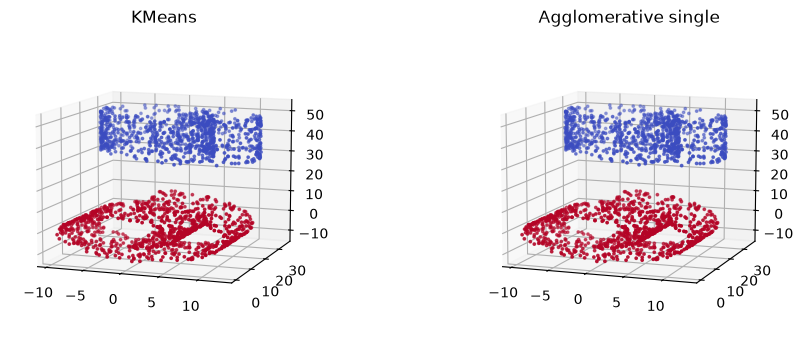

In [9]:
# The slides' second challenge: separate the two swiss rolls (hint: connectivity-aware methods win)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), subplot_kw={"projection": "3d"})
for ax, (name, algo) in zip(axes, {"KMeans": KMeans(2, n_init=10, random_state=0),
                                    "Agglomerative single": AgglomerativeClustering(2, linkage="single")}.items()):
    lab = algo.fit_predict(two_rolls)
    ax.scatter(*two_rolls.T, c=lab, s=3, cmap="coolwarm"); ax.set_title(name); ax.view_init(10, -70)
plt.show()

## 4. The curse of dimensionality (Bellman, 1961)
To keep the same *density* of samples, you need exponentially more data as dimensions are added. In high
dimensions distances concentrate: nearest and farthest neighbours become almost equally far.

In [10]:
for d in [1, 2, 10, 100, 1000]:
    P = rng.random((500, d))
    dd = pairwise.euclidean_distances(P[:1], P[1:])[0]
    print(f"d={d:>4}: min/max distance ratio = {dd.min() / dd.max():.2f}   "
          f"fraction of unit-cube volume within 0.1 of the border: {1 - 0.8 ** d:.3f}")

d=   1: min/max distance ratio = 0.00   fraction of unit-cube volume within 0.1 of the border: 0.200
d=   2: min/max distance ratio = 0.03   fraction of unit-cube volume within 0.1 of the border: 0.360
d=  10: min/max distance ratio = 0.27   fraction of unit-cube volume within 0.1 of the border: 0.893
d= 100: min/max distance ratio = 0.73   fraction of unit-cube volume within 0.1 of the border: 1.000
d=1000: min/max distance ratio = 0.91   fraction of unit-cube volume within 0.1 of the border: 1.000


Remedies: use prior knowledge, smooth the target function, **reduce the dimensionality** (feature selection or
feature extraction / subspace methods: PCA, LDA, ICA).

## 5. Principal Component Analysis (PCA)
Find orthogonal directions of **maximum variance**. If $S=\sum_k (x_k-m)(x_k-m)^T$ is the scatter matrix, the best
1-D direction $e$ maximises $e^T S e$ subject to $\|e\|=1$ -> $Se=\lambda e$: the **eigenvectors of the covariance
matrix**, ordered by eigenvalue (= variance explained). Uses: visualisation, compression, filtering, decorrelation.
PCA is sensitive to scale: **standardise** features first when units differ.

[[-2.6841  0.3194]
 [-2.7141 -0.177 ]] [0.925 0.053] [[ 0.361 -0.085  0.857  0.358]
 [ 0.657  0.73  -0.173 -0.075]]
eigvals: [4.228 0.243 0.078 0.024] | ratio: [0.925 0.053 0.017 0.005]
matches sklearn up to sign: True


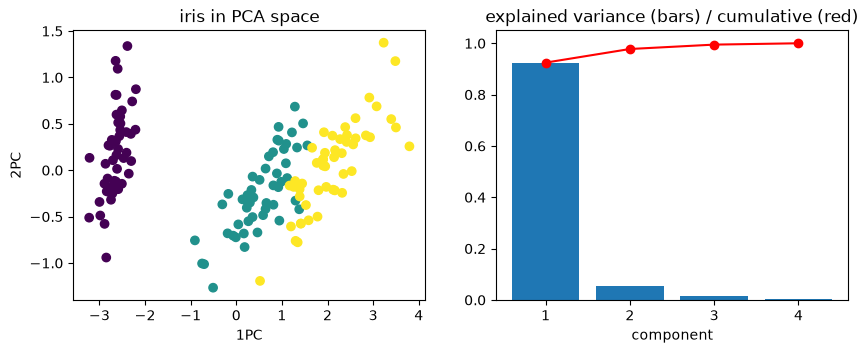

In [11]:
from sklearn import decomposition, preprocessing

pca = decomposition.PCA(n_components=2).fit(X)
T = pca.transform(X)
print(T[:2].round(4), pca.explained_variance_ratio_.round(3), pca.components_.round(3))

# By hand: eigendecomposition of the covariance matrix
Xc_ = X - X.mean(0)
eigval, eigvec = np.linalg.eigh(np.cov(Xc_.T))
order = np.argsort(eigval)[::-1]
print("eigvals:", eigval[order].round(3), "| ratio:", (eigval[order] / eigval.sum()).round(3))
print("matches sklearn up to sign:", np.allclose(np.abs(eigvec[:, order[:2]].T), np.abs(pca.components_)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(T[:, 0], T[:, 1], c=y); axes[0].set(xlabel="1PC", ylabel="2PC", title="iris in PCA space")
full = decomposition.PCA().fit(X)
axes[1].bar(range(1, 5), full.explained_variance_ratio_); axes[1].plot(range(1, 5), full.explained_variance_ratio_.cumsum(), "ro-")
axes[1].set(title="explained variance (bars) / cumulative (red)", xlabel="component")
plt.show()

### LDA - supervised dimensionality reduction
Linear Discriminant Analysis looks for the projection $y=w^Tx$ that maximises the Fisher criterion
$J(w)=\dfrac{w^T S_B w}{w^T S_W w}$ (between-class over within-class scatter). PCA ignores labels, LDA uses them.

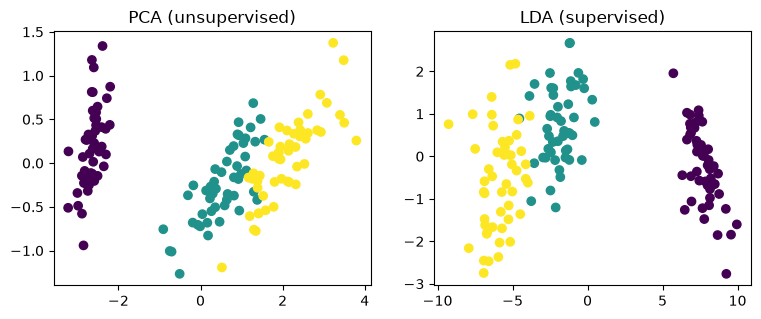

In [12]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2).fit(X, y)
L = lda.transform(X)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].scatter(T[:, 0], T[:, 1], c=y); axes[0].set_title("PCA (unsupervised)")
axes[1].scatter(L[:, 0], L[:, 1], c=y); axes[1].set_title("LDA (supervised)")
plt.show()

## 6. Supervised learning: classification
Learn the link between data `X` and targets `y`.

### k-nearest neighbours (a *lazy* learner)
Classify a sample by majority vote among its `k` closest training points. No training phase, expensive prediction.
The decision regions form a Voronoi-like tessellation. Small `k` -> jagged boundary (high variance); large `k` -> smooth
(high bias).

### Support Vector Classifier
Maximum-margin separating surface; the **RBF kernel** gives non-linear boundaries. Hyper-parameters: `C`
(penalty for margin violations), `gamma` (kernel width).

In [13]:
from sklearn import neighbors, svm

knn = neighbors.KNeighborsClassifier(n_neighbors=7).fit(T, y)
print(knn.predict([[0.1, 0.2]]), (knn.predict(T) == y).mean())
svc = svm.SVC(kernel="rbf", gamma=0.7, C=1).fit(T, y)
print(svc.predict([[-0.7, 7]]), (svc.predict(T) == y).mean(), "<- resubstitution accuracy is optimistic!")

[1] 0.98
[2] 0.9533333333333334 <- resubstitution accuracy is optimistic!


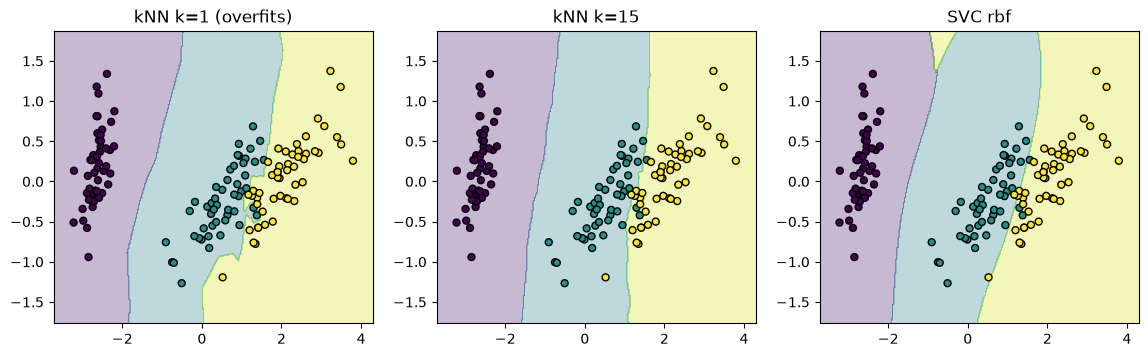

In [14]:
# Challenge (slides): decision boundaries of kNN and SVC on the 2-D PCA of iris -> np.meshgrid
def plot_boundary(clf, X2, y2, ax, title):
    xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 300),
                         np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 300))
    zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap="viridis")
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, edgecolor="k", s=25, cmap="viridis")
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
plot_boundary(neighbors.KNeighborsClassifier(1).fit(T, y), T, y, axes[0], "kNN k=1 (overfits)")
plot_boundary(neighbors.KNeighborsClassifier(15).fit(T, y), T, y, axes[1], "kNN k=15")
plot_boundary(svm.SVC(gamma=0.7, C=1).fit(T, y), T, y, axes[2], "SVC rbf")
plt.show()

## 7. Evaluation: metrics
Accuracy hides class-specific errors. From the **confusion matrix** (rows = true, columns = predicted):

* **Precision** = TP / (TP + FP): of what I selected, how much is relevant?
* **Recall** (sensitivity) = TP / (TP + FN): of what is relevant, how much did I select?
* **F1** = 2PR / (P + R): harmonic mean. **ROC/AUC** and **precision-recall curves** for score thresholds;
  **MCC** for imbalanced binary problems.

In [15]:
from sklearn import metrics

y_pred = svc.predict(T)
print(metrics.confusion_matrix(y, y_pred))                         # note the order: (y_true, y_pred)
print(metrics.classification_report(y, y_pred, target_names=iris.target_names))
print("accuracy", metrics.accuracy_score(y, y_pred), "| recall per class", metrics.recall_score(y, y_pred, average=None).round(3),
      "| MCC", round(metrics.matthews_corrcoef(y, y_pred), 3))

[[50  0  0]
 [ 0 47  3]
 [ 0  4 46]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.92      0.94      0.93        50
   virginica       0.94      0.92      0.93        50

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

accuracy 0.9533333333333334 | recall per class [1.   0.94 0.92] | MCC 0.93


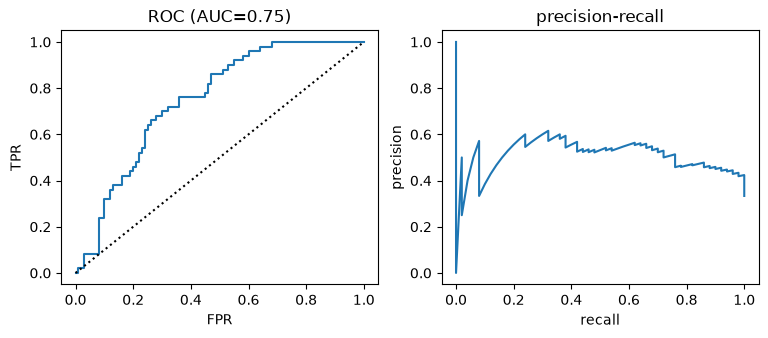

In [16]:
# ROC curve for a binary problem (class 1 vs rest) using predicted probabilities
from sklearn.linear_model import LogisticRegression
yb_ = (y == 1).astype(int)
clf = LogisticRegression().fit(T, yb_)
fpr, tpr, thr = metrics.roc_curve(yb_, clf.predict_proba(T)[:, 1])
prec, rec, _ = metrics.precision_recall_curve(yb_, clf.predict_proba(T)[:, 1])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set(title=f"ROC (AUC={metrics.auc(fpr, tpr):.2f})", xlabel="FPR", ylabel="TPR")
axes[1].plot(rec, prec); axes[1].set(title="precision-recall", xlabel="recall", ylabel="precision")
plt.show()

## 8. Validation and over-fitting
*Over-fitting*: a model with many parameters relative to the number of samples can fit even noise perfectly, so its
score on the training data says nothing about **new** data. Always evaluate on data not used for fitting:
**hold-out** (`train_test_split`), **k-fold cross-validation**, **leave-one-out**, and a final untouched **test set**.
Any data-dependent step (scaling, PCA, feature selection, tuning!) must be fitted **inside** the training folds,
otherwise information leaks - use a `Pipeline`.

In [17]:
from sklearn.model_selection import train_test_split, cross_val_score, LeaveOneOut, KFold, StratifiedKFold

xTrain, xVal, yTrain, yVal = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
print(xTrain.shape, xVal.shape)
knn = neighbors.KNeighborsClassifier(7).fit(xTrain, yTrain)
print("hold-out accuracy:", (knn.predict(xVal) == yVal).mean())

recalls = cross_val_score(neighbors.KNeighborsClassifier(1), X, y, cv=6)
print(recalls.round(2), recalls.mean().round(3), "+/-", recalls.std().round(3))

loo_scores = cross_val_score(svm.SVC(kernel="linear", C=1), X, y, cv=LeaveOneOut())
print("LOO accuracy:", loo_scores.mean().round(3), "over", len(loo_scores), "fits")

(90, 4) (60, 4)
hold-out accuracy: 0.9833333333333333
[0.96 1.   0.88 0.96 0.96 1.  ] 0.96 +/- 0.04


LOO accuracy: 0.98 over 150 fits


In [18]:
# Over-fitting demonstrated: 100 pure-noise features, labels random -> a flexible model "learns" the training set
Xn = rng.normal(size=(60, 100)); yn = rng.integers(0, 2, 60)
knn1 = neighbors.KNeighborsClassifier(1)
tree = __import__("sklearn.tree", fromlist=["DecisionTreeClassifier"]).DecisionTreeClassifier(random_state=0)
for name, m in [("1-NN", knn1), ("deep tree", tree)]:
    train_acc = m.fit(Xn, yn).score(Xn, yn)
    cv_acc = cross_val_score(m, Xn, yn, cv=5).mean()
    print(f"{name:>10}: train accuracy {train_acc:.2f} | cross-validated {cv_acc:.2f}  (chance = 0.50)")

      1-NN: train accuracy 1.00 | cross-validated 0.50  (chance = 0.50)
 deep tree: train accuracy 1.00 | cross-validated 0.57  (chance = 0.50)


## 9. Pipelines and hyper-parameter search
A `Pipeline` chains transformers and a final estimator into a single estimator, so cross-validation refits every step
on each training fold. `GridSearchCV` / `RandomizedSearchCV` tune hyper-parameters with nested validation.

In [19]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("scale", preprocessing.StandardScaler()),
                 ("pca", decomposition.PCA(n_components=2)),
                 ("clf", svm.SVC())])
grid = GridSearchCV(pipe, {"pca__n_components": [1, 2, 3, 4], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.1, 1]},
                    cv=StratifiedKFold(5, shuffle=True, random_state=0))
grid.fit(xTrain, yTrain)
print(grid.best_params_, round(grid.best_score_, 3), "| held-out test:", round(grid.score(xVal, yVal), 3))

{'clf__C': 1, 'clf__gamma': 0.1, 'pca__n_components': 4} 0.956 | held-out test: 0.967


## 10. Regression in two minutes

In [20]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

Xd, yd = datasets.load_diabetes(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.3, random_state=0)
for name, model in [("linear", LinearRegression()), ("ridge", Ridge(alpha=1.0)), ("random forest", RandomForestRegressor(200, random_state=0))]:
    pred = model.fit(Xtr, ytr).predict(Xte)
    print(f"{name:>14}: RMSE {mean_squared_error(yte, pred) ** 0.5:6.2f}   R2 {r2_score(yte, pred):.3f}")

        linear: RMSE  55.65   R2 0.393
         ridge: RMSE  56.91   R2 0.365


 random forest: RMSE  59.09   R2 0.316


## 11. Practical session: "Eigendigits" (the Eigenfaces recipe)
The original session: 350 deputies' photos (86x85 px = 7310 features) -> class `Diputado`/`Parlament` -> scale -> PCA ->
*eigen-faces* -> k-means on the scores -> non-linear classifier for gender. We follow exactly the same steps with the
1 797 handwritten digits (8x8 = 64 features).

(1797, 64) (1797, 8, 8)


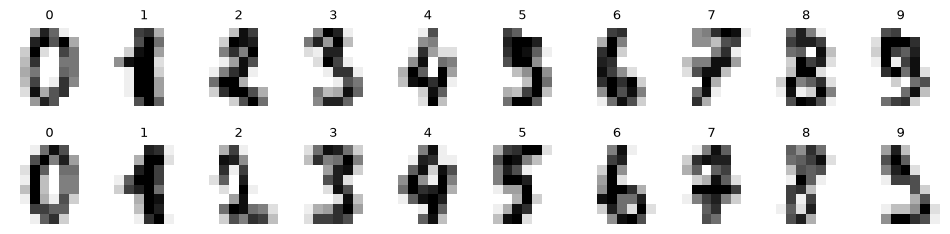

In [21]:
digits = datasets.load_digits()
Xd_, yd_ = digits.data, digits.target
print(Xd_.shape, digits.images.shape)

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.show()

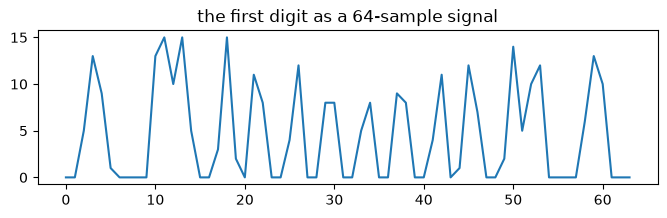

[0.12  0.096 0.084 0.065 0.049 0.042 0.039 0.034 0.03  0.029] cumulative: 0.59


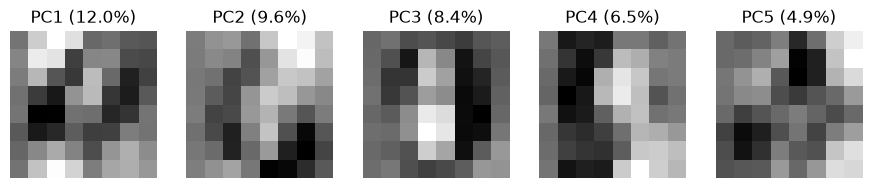

In [22]:
# Everything is a signal: an image is just a vector of 64 numbers
fig, ax = plt.subplots(figsize=(8, 2)); ax.plot(Xd_[0]); ax.set_title("the first digit as a 64-sample signal"); plt.show()

# standardise -> PCA
sX = preprocessing.StandardScaler().fit_transform(Xd_)
ncomp = 10
mod = decomposition.PCA(n_components=ncomp).fit(sX)
ev = mod.explained_variance_ratio_
print(ev.round(3), "cumulative:", ev.cumsum().round(2)[-1])
Xpca = mod.transform(sX)

# the principal components, as images ("eigen-digits")
fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(mod.components_[i].reshape(8, 8), cmap="gray"); ax.set_title(f"PC{i + 1} ({ev[i]:.1%})"); ax.axis("off")
plt.show()

cluster/label agreement (adjusted Rand): 0.485


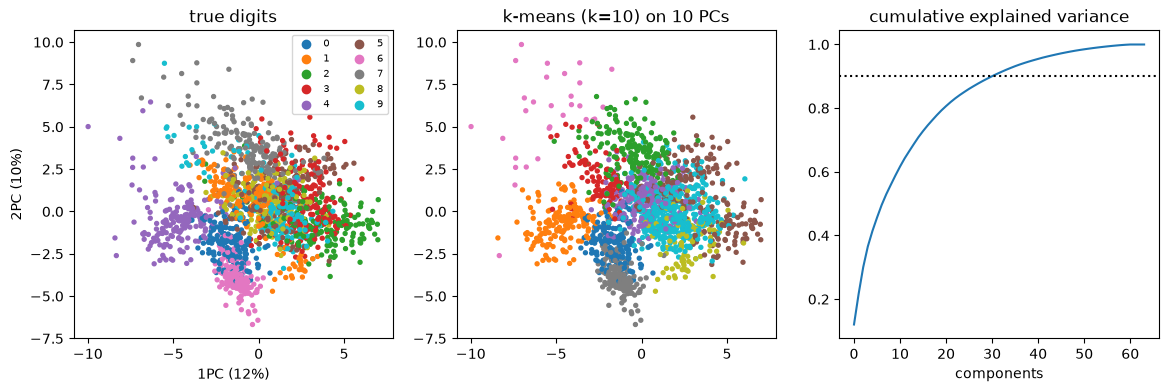

components for 90% variance: 31


In [23]:
# Score plot, k-means on the PCA scores, and reconstruction with few components
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sc = axes[0].scatter(Xpca[:, 0], Xpca[:, 1], c=yd_, cmap="tab10", s=8)
axes[0].legend(*sc.legend_elements(), ncol=2, fontsize=7); axes[0].set(xlabel=f"1PC ({ev[0]:.0%})", ylabel=f"2PC ({ev[1]:.0%})", title="true digits")
kmd = KMeans(10, n_init=10, random_state=0).fit(Xpca)
axes[1].scatter(Xpca[:, 0], Xpca[:, 1], c=kmd.labels_, cmap="tab10", s=8); axes[1].set_title("k-means (k=10) on 10 PCs")
from sklearn.metrics import adjusted_rand_score
print("cluster/label agreement (adjusted Rand):", round(adjusted_rand_score(yd_, kmd.labels_), 3))

full_pca = decomposition.PCA().fit(sX)
axes[2].plot(full_pca.explained_variance_ratio_.cumsum()); axes[2].axhline(0.9, ls=":", c="k")
axes[2].set(title="cumulative explained variance", xlabel="components")
plt.show()
print("components for 90% variance:", int(np.argmax(full_pca.explained_variance_ratio_.cumsum() >= 0.9)) + 1)

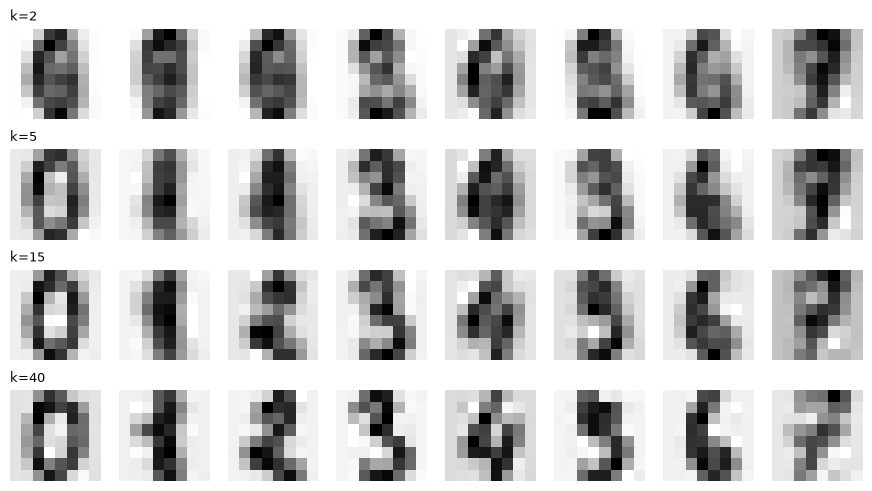

In [24]:
# Reconstruction: project onto k components and back
fig, axes = plt.subplots(4, 8, figsize=(11, 6))
for row, k in enumerate([2, 5, 15, 40]):
    p = decomposition.PCA(n_components=k).fit(sX)
    recon = p.inverse_transform(p.transform(sX[:8]))
    recon = recon * Xd_.std(0).clip(min=1e-9) + Xd_.mean(0)                  # undo the scaling for display
    for col in range(8):
        axes[row, col].imshow(recon[col].reshape(8, 8), cmap="gray_r"); axes[row, col].axis("off")
    axes[row, 0].set_title(f"k={k}", loc="left", fontsize=9)
plt.show()

          kNN(5): CV 0.968 +/- 0.013 | test 0.970
 PCA(20)+SVC rbf: CV 0.972 +/- 0.009 | test 0.980


      SVC linear: CV 0.975 +/- 0.009 | test 0.981
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        54
           1      0.964     0.964     0.964        55
           2      1.000     0.981     0.990        53
           3      1.000     0.982     0.991        55
           4      0.931     1.000     0.964        54
           5      0.982     1.000     0.991        55
           6      0.981     0.963     0.972        54
           7      1.000     1.000     1.000        54
           8      0.944     0.981     0.962        52
           9      1.000     0.926     0.962        54

    accuracy                          0.980       540
   macro avg      0.980     0.980     0.980       540
weighted avg      0.980     0.980     0.980       540



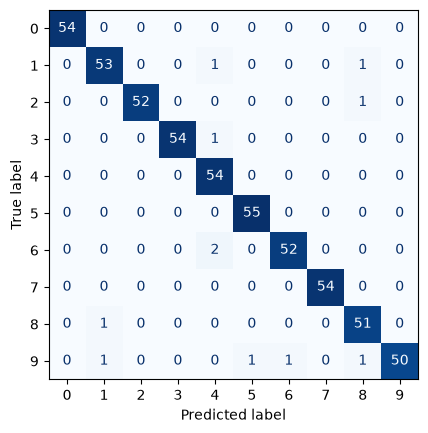

In [25]:
# Non-linear classifier + proper validation (the slides' "gender" step -> here: the digit)
Xtr, Xte, ytr, yte = train_test_split(Xd_, yd_, test_size=0.3, random_state=0, stratify=yd_)
models = {
    "kNN(5)": make_pipeline(preprocessing.StandardScaler(), neighbors.KNeighborsClassifier(5)),
    "PCA(20)+SVC rbf": make_pipeline(preprocessing.StandardScaler(), decomposition.PCA(20), svm.SVC(gamma="scale", C=10)),
    "SVC linear": make_pipeline(preprocessing.StandardScaler(), svm.SVC(kernel="linear")),
}
for name, m in models.items():
    cv = cross_val_score(m, Xtr, ytr, cv=5)
    print(f"{name:>16}: CV {cv.mean():.3f} +/- {cv.std():.3f} | test {m.fit(Xtr, ytr).score(Xte, yte):.3f}")

best = models["PCA(20)+SVC rbf"]
print(metrics.classification_report(yte, best.predict(Xte), digits=3))
metrics.ConfusionMatrixDisplay.from_estimator(best, Xte, yte, cmap="Blues", colorbar=False)
plt.show()

## 12. Persisting models

In [26]:
import joblib, tempfile, os
path = os.path.join(tempfile.gettempdir(), "digits_model.joblib")
joblib.dump(best, path)
reloaded = joblib.load(path)
print(reloaded.score(Xte, yte)); os.remove(path)

0.9796296296296296


## Exercises

**A. Implement kNN from scratch** (vectorised distance matrix + `np.argpartition` + majority vote) and match
`KNeighborsClassifier` accuracy on iris. Time both on `make_classification(20000, 20)`.

**B. PCA from scratch** with `np.linalg.svd`; reproduce `explained_variance_ratio_` and the scores (up to sign) of
sklearn on the digits.

**C. Leakage experiment.** On pure-noise data (as in section 8) select the 10 "best" features with `SelectKBest`
*before* cross-validation vs *inside* a pipeline. Show how the first gives a falsely high accuracy.

**D. Bias/variance curve.** For kNN on `make_moons(noise=0.3)` plot train and CV accuracy against `k` = 1..60.

**E. Cluster the digits** with Agglomerative and DBSCAN too; compare with k-means using the adjusted Rand index.

**F. Learning curves** (`sklearn.model_selection.learning_curve`) for the SVC on digits - is more data worth it?

In [27]:
# Your turn